# Monte Carlo Comparison with Inverse-Covariance Portfolios

A known covariance lets each fitted portfolio be evaluated under the same population risk:

$$
\rho_{b,m}=\frac{\widehat w_{b,m}^{\mathsf T}\Sigma_0\widehat w_{b,m}}{w_0^{\mathsf T}\Sigma_0w_0},
\qquad
E_{b,m}=\left\lVert\widehat w_{b,m}-w_{0,m}\right\rVert_1.
$$

Here, $b$ labels a generated training sample, $m$ labels a portfolio rule, $\widehat w_{b,m}$ is its fitted weight vector, $\Sigma_0$ is the known covariance, $w_0$ is the known minimum-variance portfolio, $\rho_{b,m}$ is the true-risk ratio, $w_{0,m}$ is method $m$ applied to population inputs, and $E_{b,m}$ is allocation error relative to that method's own population-input weights.

Row,Quantity,Value
,String,Float64
1,Assets,24.0
2,Clusters,4.0
3,Assets per cluster,6.0
4,Within-cluster correlation,0.6
5,Between-cluster correlation,0.05
6,Training observations,126.0
7,Repetitions,60.0
8,Random seed,2103.0


Row,Method,Mean true-risk ratio,Median true-risk ratio,Risk-ratio standard deviation,Mean allocation error,Median allocation error,Mean concentration,Mean largest absolute weight
,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,Equal weight,1.35898,1.35898,4.47837e-16,0.0,0.0,0.0416667,0.0416667
2,HRP,1.07684,1.07314,0.0160271,0.299038,0.307722,0.0577635,0.113042
3,Inverse variance,1.06283,1.06231,0.00657742,0.0920425,0.0918073,0.0537025,0.09648
4,Minimum variance,1.22097,1.2131,0.080068,1.14695,1.09908,0.209803,0.268066


Row,Comparison,Mean paired risk-ratio difference,Share with lower HRP risk
,String,Float64,Float64
1,HRP minus minimum variance,-0.144135,1.0
2,HRP minus inverse variance,0.0140103,0.116667
3,HRP minus equal weight,-0.28214,1.0


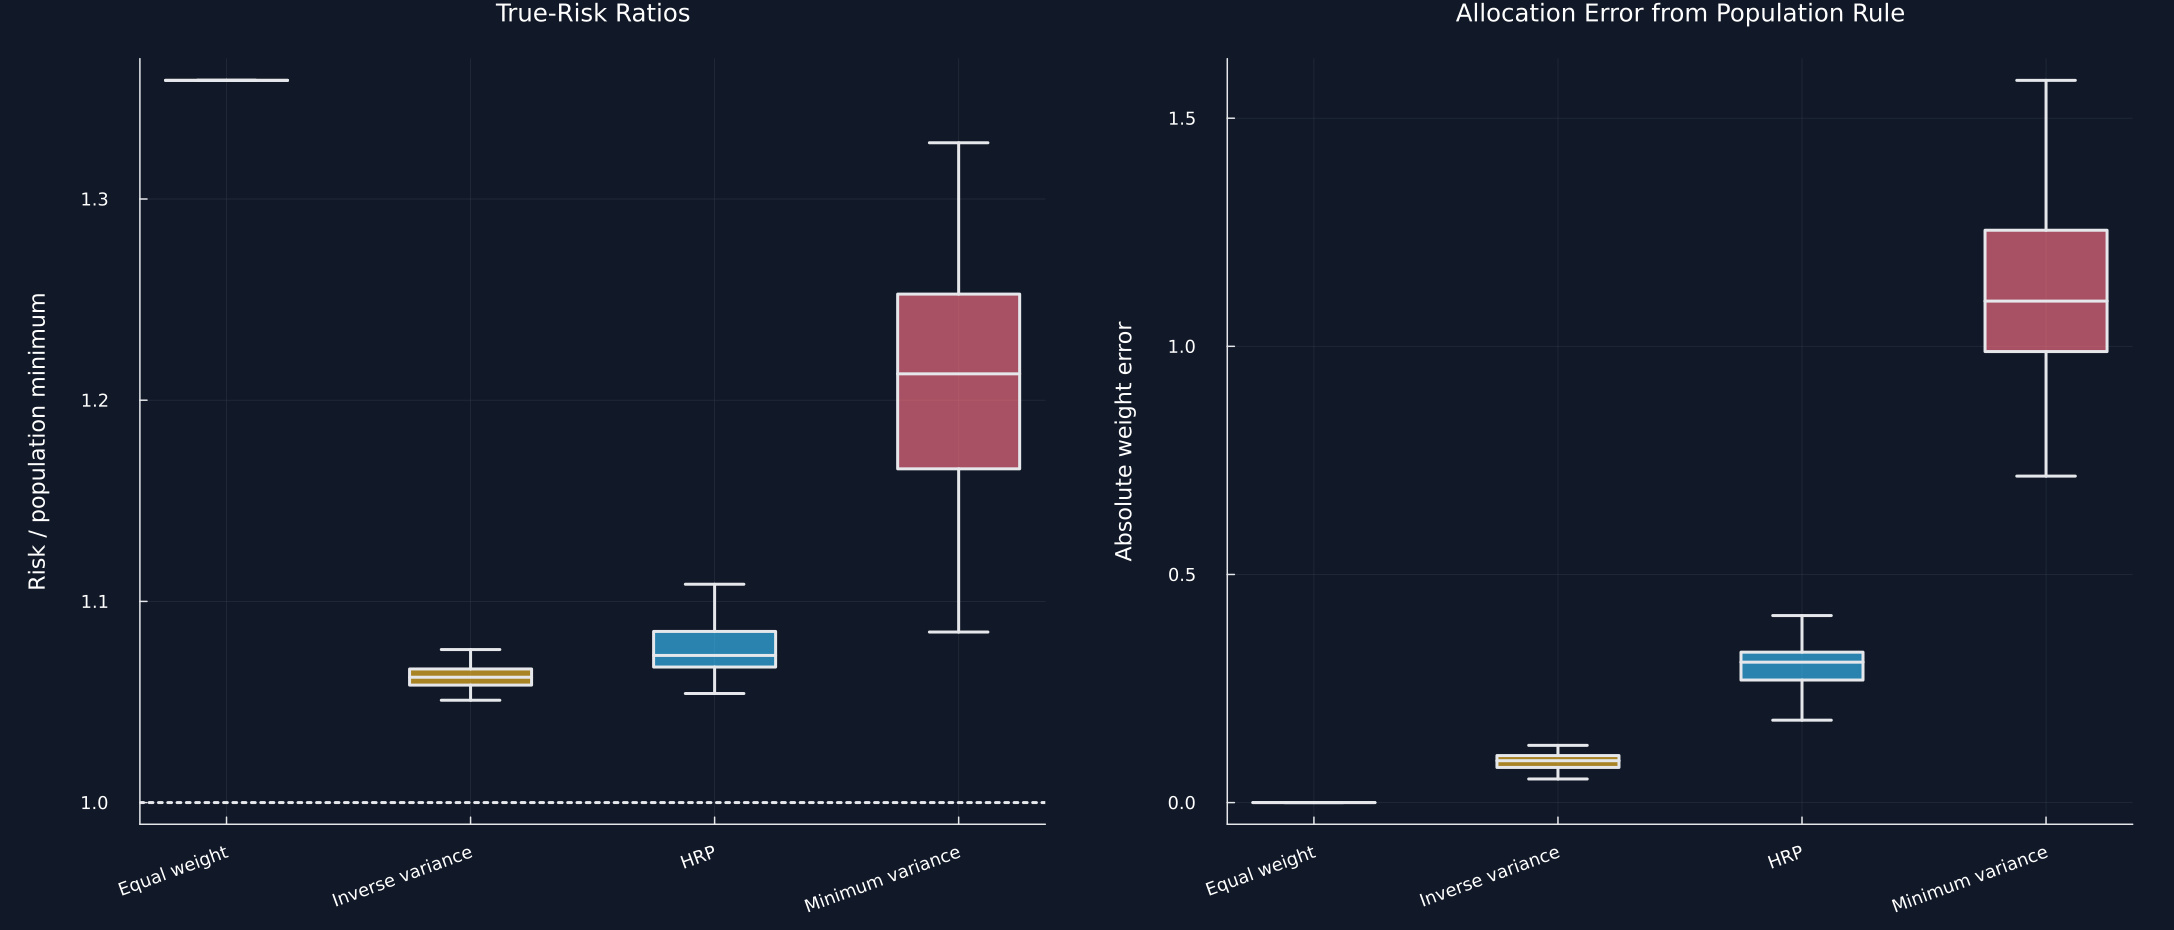

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("25_hierarchical_risk_parity");
using CSV, TOML, Printf
default(left_margin=10Plots.mm,bottom_margin=8Plots.mm)
include(joinpath("..","support","BookHierarchy.jl"))
using .BookHierarchy
using RiskLabAI.Optimization: cluster_variance,hrp,inverse_variance_weights,recursive_bisection
violet = "#C084FC"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter21-"*replace(name,"_"=>"-"))
matrix_data(values) = DataFrame(values,:auto)
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
lines = readlines(data_path)
first_row = findfirst(line->startswith(line,",Agric"),lines)
last_row = findnext(line->isempty(strip(line)),lines,first_row+1)
raw = CSV.read(IOBuffer(join(lines[first_row:last_row-1],"\n")),DataFrame)
all_dates = Date.(string.(raw[!,1]),dateformat"yyyymmdd")
all_values = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all(all_values.>-99;dims=2))
dates = all_dates[valid]
selected_assets = names(raw)[2:17]
public_sample = all_values[valid,1:16]/100
annual_covariance,public_correlation = cov(public_sample)*252,cor(public_sample)
function matrix_panel(values,labels,title;limits=nothing,color=:magma)
    n = length(labels)
    return heatmap(1:n,1:n,values;title,color,clims=isnothing(limits) ? extrema(values) : limits,yflip=true,xticks=(1:n,labels),yticks=(1:n,labels),xrotation=90,tickfontsize=7,xlims=(0.5,n+0.5),ylims=(0.5,n+0.5),widen=false)
end
function tree_panel(tree,order,labels,title)
    n = length(labels)
    positions,heights = zeros(2n-1),zeros(2n-1)
    positions[order] = 1:n
    figure = plot(;title,xlim=(0.3,n+0.7),ylim=(0,1.08*maximum(tree[:,3])),xticks=(1:n,labels[order]),xrotation=90,tickfontsize=7,ylabel="Merge distance",legend=false)
    for step in axes(tree,1)
        left,right = Int.(tree[step,1:2]).+1
        height = tree[step,3]
        plot!(figure,[positions[left],positions[left],positions[right],positions[right]],[heights[left],height,height,heights[right]];color=palette.cyan)
        positions[n+step],heights[n+step] = (positions[left]+positions[right])/2,height
    end
    return figure
end
path_length(distance,order) = sum(distance[order[i],order[i+1]] for i in 1:length(order)-1)
turnover(a,b) = 0.5*sum(abs,a-b)
finite_mean(values) = mean(filter(isfinite,values))
function box_summary!(figure,groups,colors)
    for (index,values) in enumerate(groups)
        lower,middle,upper = quantile(values,[.25,.5,.75])
        spread = upper-lower
        bottom = minimum(values[values.>=lower-1.5spread])
        top = maximum(values[values.<=upper+1.5spread])
        plot!(figure,Shape([index-.25,index+.25,index+.25,index-.25],[lower,lower,upper,upper]);color=colors[index],fillalpha=.65,linecolor=palette.text,label=false)
        plot!(figure,[index-.25,index+.25],[middle,middle];color=palette.text,label=false)
        plot!(figure,[index,index],[bottom,lower];color=palette.text,label=false)
        plot!(figure,[index,index],[upper,top];color=palette.text,label=false)
        for height in (bottom,top)
            plot!(figure,[index-.12,index+.12],[height,height];color=palette.text,label=false)
        end
    end
    return figure
end
random_root = joinpath("..","data","chapter25_random_inputs")
random_manifest = TOML.parsefile(joinpath(random_root,"inputs.toml"))["files"]
for (name,record) in random_manifest
end
conventions = TOML.parsefile(joinpath(random_root,"coordinate_convention.toml"))["families"]
function random_samples(n,training,within,filename)
    covariance,_ = clustered_covariance(n,4,within,0.05)
    normals = Matrix{Float64}(CSV.read(joinpath(random_root,filename),DataFrame))
    orientation = conventions[string(n)*"_"*string(Int(within*100))]["orientation"]
    return generator_samples(covariance,normals,orientation)
end
true_covariance,true_correlation = clustered_covariance(24,4,0.6,0.05)
population_weights = Dict(portfolio_set(true_covariance,true_correlation))
true_minimum_weights = population_weights["Minimum variance"]
true_minimum_variance = dot(true_minimum_weights,true_covariance*true_minimum_weights)
design_table = DataFrame("Quantity"=>["Assets","Clusters","Assets per cluster","Within-cluster correlation","Between-cluster correlation","Training observations","Repetitions","Random seed"],"Value"=>[24,4,6,0.6,0.05,126,60,2103])
table(design_table,"known_truth_design","Known clustered covariance design.")
repeated_samples = random_samples(24,126,0.6,"repeated_normals.csv")
repeated_rows = NamedTuple[]
for repetition in 1:60
    samples = repeated_samples[((repetition-1)*126 .+ (1:126)),:]
    for (method,weights) in portfolio_set(cov(samples),cor(samples))
        push!(repeated_rows,(Repetition=repetition,Method=method,risk=dot(weights,true_covariance*weights)/true_minimum_variance,error=sum(abs,weights-population_weights[method]),concentration=sum(abs2,weights),largest=maximum(abs,weights)))
    end
end
repeated_results = DataFrame(repeated_rows)
rename!(repeated_results,["Repetition","Method","True-risk ratio","Allocation absolute error","Weight concentration","Largest absolute weight"])
save_data(repeated_results,paths,"repeated_results")
method_order = ["Equal weight","Inverse variance","HRP","Minimum variance"]
colors = [palette.green,palette.amber,palette.cyan,palette.rose]
summary_rows = NamedTuple[]
for method in sort(method_order)
    subset = repeated_results[repeated_results.Method.==method,:]
    push!(summary_rows,(Method=method,meanrisk=mean(subset[!,3]),medianrisk=median(subset[!,3]),sd=std(subset[!,3]),meanerror=mean(subset[!,4]),medianerror=median(subset[!,4]),concentration=mean(subset[!,5]),largest=mean(subset[!,6])))
end
repeated_summary = DataFrame(summary_rows)
rename!(repeated_summary,["Method","Mean true-risk ratio","Median true-risk ratio","Risk-ratio standard deviation","Mean allocation error","Median allocation error","Mean concentration","Mean largest absolute weight"])
hrp_risk = repeated_results[repeated_results.Method.=="HRP",3]
paired_comparison = DataFrame("Comparison"=>["HRP minus minimum variance","HRP minus inverse variance","HRP minus equal weight"],"Mean paired risk-ratio difference"=>[mean(hrp_risk-repeated_results[repeated_results.Method.==method,3]) for method in ["Minimum variance","Inverse variance","Equal weight"]],"Share with lower HRP risk"=>[mean(hrp_risk.<repeated_results[repeated_results.Method.==method,3]) for method in ["Minimum variance","Inverse variance","Equal weight"]])
table(repeated_summary,"repeated_known_truth_summary","Repeated known-covariance portfolio results.")
table(paired_comparison,"repeated_paired_comparison","Paired true-risk comparisons with HRP.")
p1 = plot(;title="True-Risk Ratios",ylabel="Risk / population minimum",xticks=(1:4,method_order),xrotation=20,legend=false)
p2 = plot(;title="Allocation Error from Population Rule",ylabel="Absolute weight error",xticks=(1:4,method_order),xrotation=20,legend=false)
box_summary!(p1,[repeated_results[repeated_results.Method.==method,3] for method in method_order],colors)
box_summary!(p2,[repeated_results[repeated_results.Method.==method,4] for method in method_order],colors)
hline!(p1,[1.0];color=palette.text,linestyle=:dot,label=false)
save_figure(plot(p1,p2;layout=(1,2),size=(1450,620)),paths,"repeated_known_truth_portfolios")


## Testing when clusters remain stable

The dimension-to-sample ratio records how much covariance information is estimated from each training sample:

$$
q=\frac{N}{T}.
$$

Here, $N$ is the number of assets, $T$ is the number of training observations, and $q$ is larger when the covariance problem has more dimensions relative to the available history.

Row,Assets,Training observations,Within correlation,Dimension-to-sample ratio,Method,Mean true-risk ratio,Median true-risk ratio,Mean allocation error
,Int64,Int64,Float64,Float64,String,Float64,Float64,Float64
1,12,63,0.3,0.190476,HRP,1.06029,1.05693,0.248261
2,12,63,0.3,0.190476,Minimum variance,1.17938,1.16484,0.499181
3,12,63,0.6,0.190476,HRP,1.064,1.06107,0.318989
4,12,63,0.6,0.190476,Minimum variance,1.21864,1.20972,0.769963
5,12,126,0.3,0.0952381,HRP,1.03253,1.02842,0.193802
6,12,126,0.3,0.0952381,Minimum variance,1.09264,1.08424,0.35552
7,12,126,0.6,0.0952381,HRP,1.05685,1.05411,0.267372
8,12,126,0.6,0.0952381,Minimum variance,1.0891,1.08543,0.47275
9,12,252,0.3,0.047619,HRP,1.02753,1.02927,0.169515


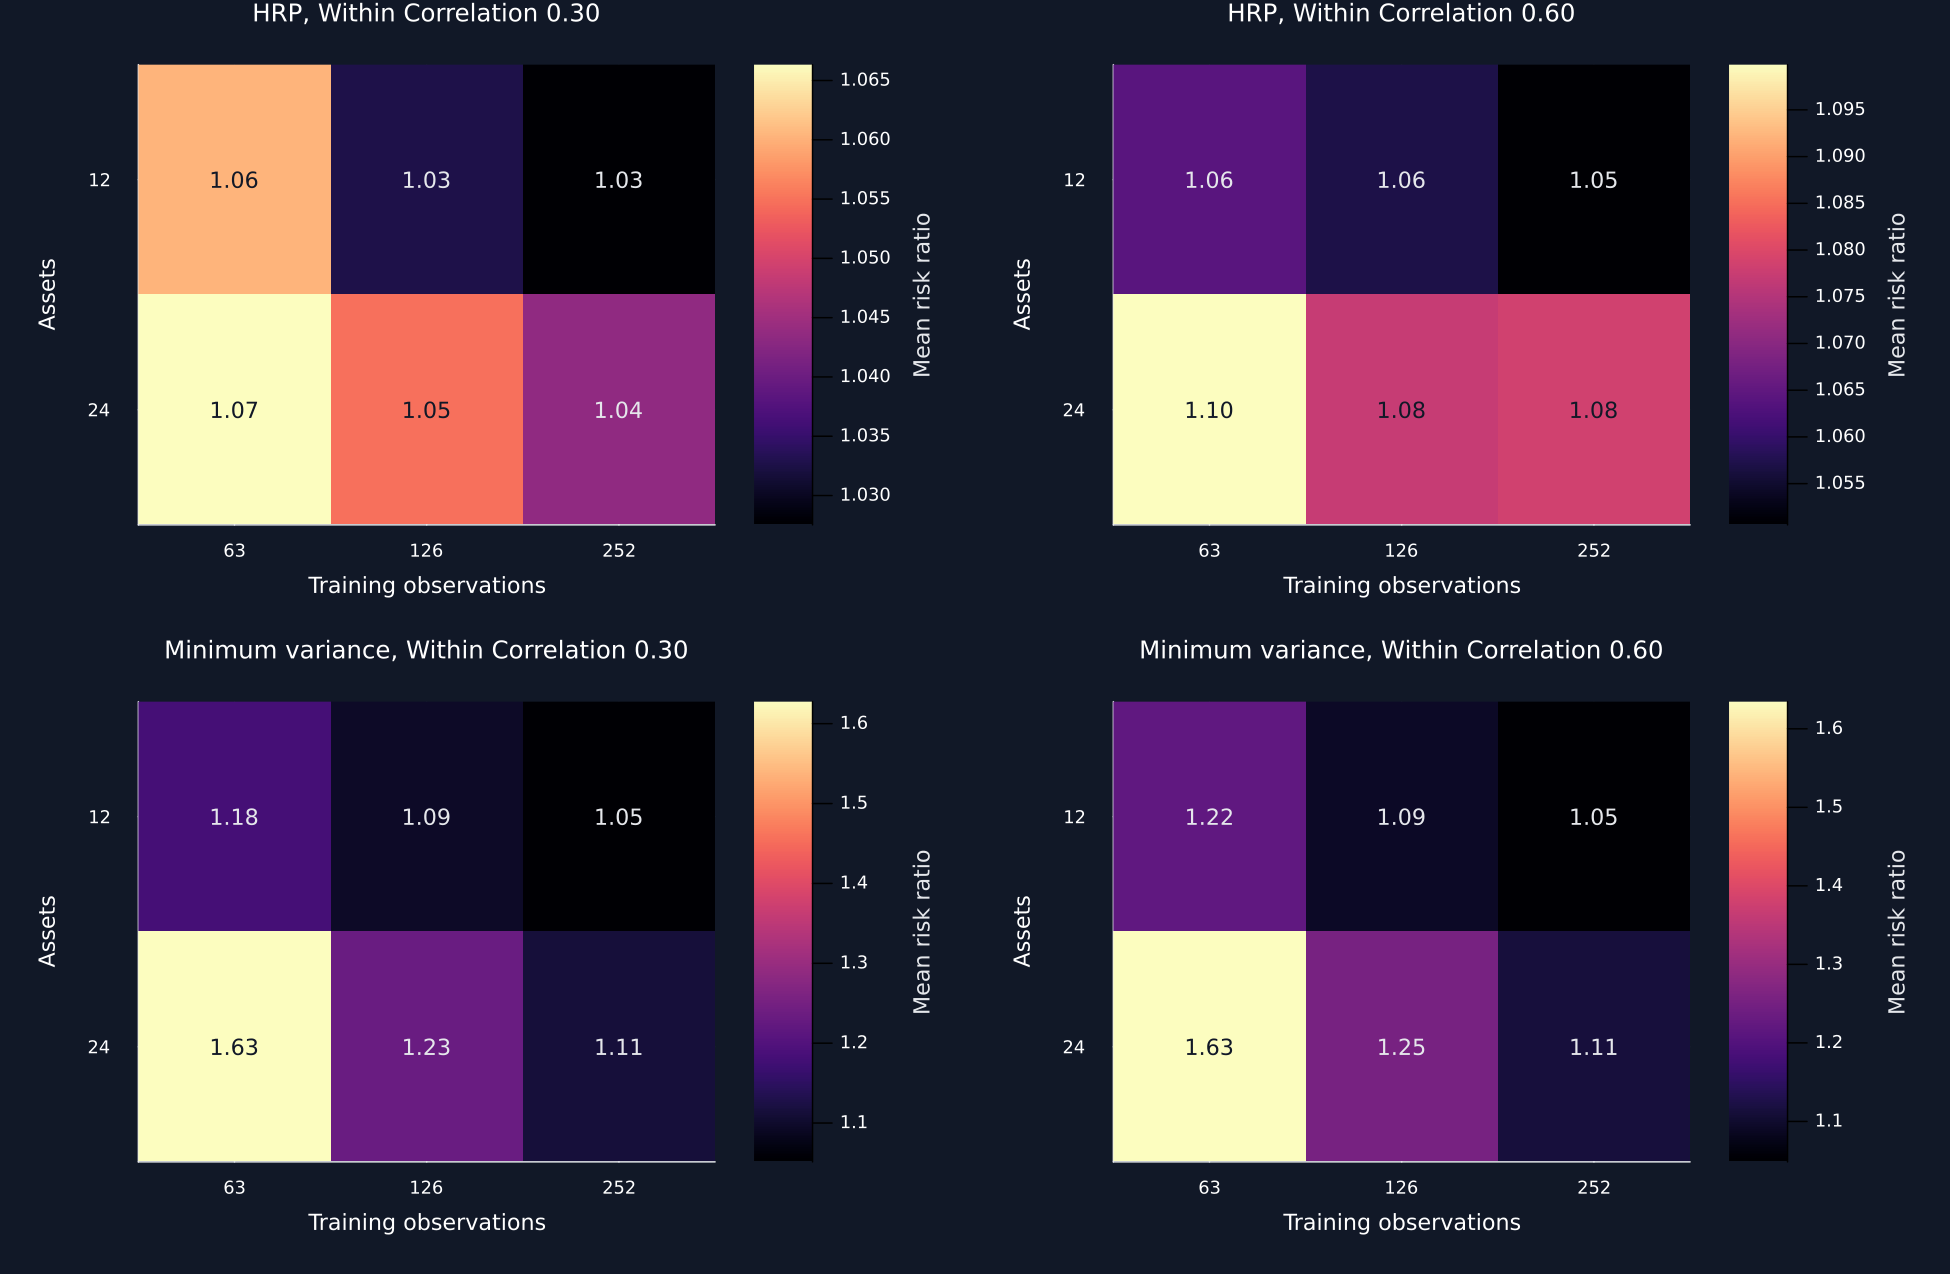

In [2]:
sensitivity_rows = NamedTuple[]
for n in [12,24],training in [63,126,252],within in [0.3,0.6]
    covariance,correlation = clustered_covariance(n,4,within,0.05)
    oracle = Dict(portfolio_set(covariance,correlation))
    minimum_variance = dot(oracle["Minimum variance"],covariance*oracle["Minimum variance"])
    filename = "sensitivity_"*string(n)*"_"*string(training)*"_"*string(Int(within*100))*".csv"
    values = random_samples(n,training,within,filename)
    for repetition in 1:20
        samples = values[((repetition-1)*training .+ (1:training)),:]
        fitted = Dict(portfolio_set(cov(samples),cor(samples)))
        for method in ["HRP","Minimum variance"]
            weights = fitted[method]
            push!(sensitivity_rows,(Assets=n,training=training,within=within,ratio=n/training,Repetition=repetition,Method=method,risk=dot(weights,covariance*weights)/minimum_variance,error=sum(abs,weights-oracle[method])))
        end
    end
end
sensitivity_results = DataFrame(sensitivity_rows)
rename!(sensitivity_results,["Assets","Training observations","Within correlation","Dimension-to-sample ratio","Repetition","Method","True-risk ratio","Allocation absolute error"])
save_data(sensitivity_results,paths,"sensitivity_results")
sensitivity_summary = combine(groupby(sensitivity_results,["Assets","Training observations","Within correlation","Dimension-to-sample ratio","Method"];sort=true),"True-risk ratio"=>mean=>"Mean true-risk ratio","True-risk ratio"=>median=>"Median true-risk ratio","Allocation absolute error"=>mean=>"Mean allocation error")
table(sensitivity_summary,"sampling_sensitivity_summary","Known-covariance sensitivity to sample size, dimension, and cluster strength.")
panels = Plots.Plot[]
for method in ["HRP","Minimum variance"],within in [0.3,0.6]
    matrix = zeros(2,3)
    for (i,n) in enumerate([12,24]),(j,training) in enumerate([63,126,252])
        selected = (sensitivity_summary.Method.==method).&(sensitivity_summary.Assets.==n).&(sensitivity_summary[!,"Training observations"].==training).&(sensitivity_summary[!,"Within correlation"].==within)
        matrix[i,j] = only(sensitivity_summary[selected,"Mean true-risk ratio"])
    end
    panel = heatmap(1:3,1:2,matrix;title=method*", Within Correlation "*@sprintf("%.2f",within),color=:magma,xticks=(1:3,["63","126","252"]),yticks=(1:2,["12","24"]),yflip=true,xlabel="Training observations",ylabel="Assets",xlims=(0.5,3.5),ylims=(0.5,2.5),widen=false,colorbar_title="Mean risk ratio")
    for i in 1:2,j in 1:3
        shade = matrix[i,j]>(minimum(matrix)+maximum(matrix))/2 ? "#111827" : palette.text
        annotate!(panel,j,i,text(@sprintf("%.2f",matrix[i,j]),10,shade))
    end
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(2,2),size=(1300,850)),paths,"sampling_sensitivity_heatmaps")


## How tree instability creates turnover

One-way turnover measures the fraction of the portfolio that changes between two weight vectors:

$$
\operatorname{TO}_k=\frac{1}{2}\left\lVert w_k-w_{k-1}\right\rVert_1.
$$

Here, $k$ labels an allocation date, $w_k$ and $w_{k-1}$ are consecutive fully invested weight vectors, $\lVert\cdot\rVert_1$ is the sum of absolute changes, and $\operatorname{TO}_k$ excludes trading costs.

Row,Fold,Estimated-tree turnover,Fixed-order turnover,Same-covariance topology gap,Estimated order equals population order
,Int64,Float64,Float64,Float64,Int64
1,1,NaN,NaN,0.115796,0
2,2,0.128951,0.0282466,0.115807,0
3,3,0.0939339,0.0240331,0.166307,0
4,4,0.146159,0.0327087,0.109399,0
5,5,0.0976602,0.0220224,0.152618,0
6,6,0.11637,0.0351452,0.127419,0
7,7,0.095513,0.0188788,0.128683,0
8,8,0.134292,0.0436815,0.102353,0
9,9,0.0699996,0.0438527,0.152064,0


Row,Quantity,Value
,String,Float64
1,Allocation dates,12.0
2,Mean estimated-tree turnover,0.116942
3,Mean fixed-order turnover,0.0307736
4,Mean same-covariance topology gap,0.121813
5,Maximum topology gap,0.166307
6,Exact population-order matches,0.0


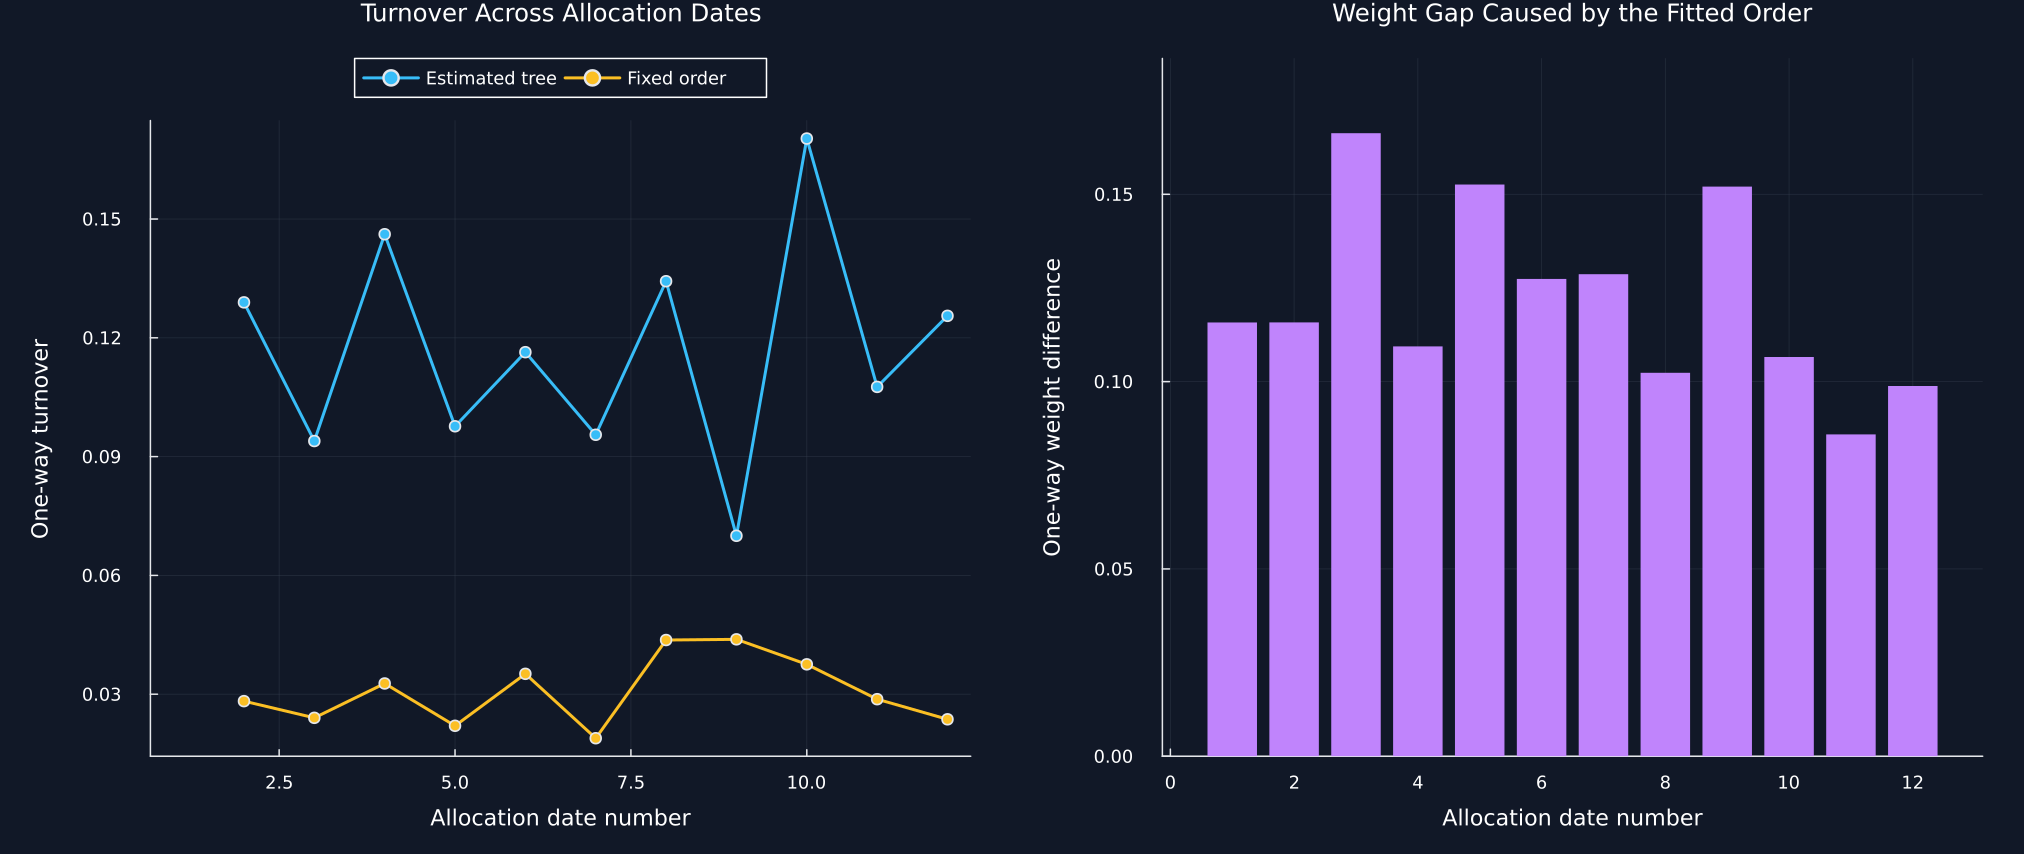

In [3]:
turnover_sample = random_samples(24,1000,0.6,"turnover_normals.csv")
_,true_tree,true_order = hierarchy(true_correlation)
topology_rows = NamedTuple[]
previous_estimated,previous_fixed = nothing,nothing
for (fold,endpoint) in enumerate(252:63:1000)
    training = turnover_sample[endpoint-251:endpoint,:]
    covariance,correlation = cov(training),cor(training)
    _,_,estimated_order = hierarchy(correlation)
    estimated_weights,fixed_weights = ordered_weights(covariance,estimated_order),ordered_weights(covariance,true_order)
    push!(topology_rows,(Fold=fold,estimated=isnothing(previous_estimated) ? NaN : turnover(estimated_weights,previous_estimated),fixed=isnothing(previous_fixed) ? NaN : turnover(fixed_weights,previous_fixed),gap=turnover(estimated_weights,fixed_weights),match=Int(estimated_order==true_order)))
    previous_estimated,previous_fixed = estimated_weights,fixed_weights
end
topology_turnover = DataFrame(topology_rows)
rename!(topology_turnover,["Fold","Estimated-tree turnover","Fixed-order turnover","Same-covariance topology gap","Estimated order equals population order"])
topology_summary = DataFrame("Quantity"=>["Allocation dates","Mean estimated-tree turnover","Mean fixed-order turnover","Mean same-covariance topology gap","Maximum topology gap","Exact population-order matches"],"Value"=>[nrow(topology_turnover),finite_mean(topology_turnover[!,2]),finite_mean(topology_turnover[!,3]),mean(topology_turnover[!,4]),maximum(topology_turnover[!,4]),sum(topology_turnover[!,5])])
table(topology_turnover,"topology_turnover_path","Turnover with estimated and fixed hierarchy orders.")
table(topology_summary,"topology_turnover_summary","Summary of hierarchy-order and turnover diagnostics.")
p1 = plot(topology_turnover.Fold,topology_turnover[!,2];color=palette.cyan,marker=:circle,label="Estimated tree",title="Turnover Across Allocation Dates",xlabel="Allocation date number",ylabel="One-way turnover",legend=:outertop,legend_columns=2)
plot!(p1,topology_turnover.Fold,topology_turnover[!,3];color=palette.amber,marker=:circle,label="Fixed order")
p2 = bar(topology_turnover.Fold,topology_turnover[!,4];color=violet,linealpha=0,legend=false,title="Weight Gap Caused by the Fitted Order",xlabel="Allocation date number",ylabel="One-way weight difference",ylims=(0,1.12*maximum(topology_turnover[!,4])))
save_figure(plot(p1,p2;layout=(1,2),size=(1350,570)),paths,"tree_turnover_diagnostics")


## Rolling Public Comparison

Held-out volatility is measured only on observations after the training window:

$$
\widehat\sigma_{k,m}^{\mathrm{test}}=\sqrt{252}\,\operatorname{sd}\!\left(R_{k}^{\mathrm{test}}w_{k,m}\right).
$$

Here, $k$ labels a chronological window, $m$ labels a portfolio rule, $R_k^{\mathrm{test}}$ is the held-out daily return matrix, $w_{k,m}$ is fitted from the earlier training window, $\operatorname{sd}$ is sample standard deviation, and 252 annualizes daily volatility.

Row,Quantity,Value
,String,String
1,Assets,16
2,Training observations,252
3,Held-out observations,63
4,Windows,23
5,Annualization factor,252
6,Costs included,No


Row,Method,Mean held-out volatility,Median held-out volatility,Lowest-volatility folds,Mean turnover,Median concentration,Median largest absolute weight
,String,Float64,Float64,Int64,Float64,Float64,Float64
1,Equal weight,0.173072,0.150928,0,0.0,0.0625,0.0625
2,HRP,0.154705,0.132578,3,0.0794887,0.0783245,0.124907
3,Inverse variance,0.154591,0.134209,6,0.0389922,0.0771178,0.117342
4,Minimum variance,0.148145,0.133422,14,0.437995,0.356611,0.426548


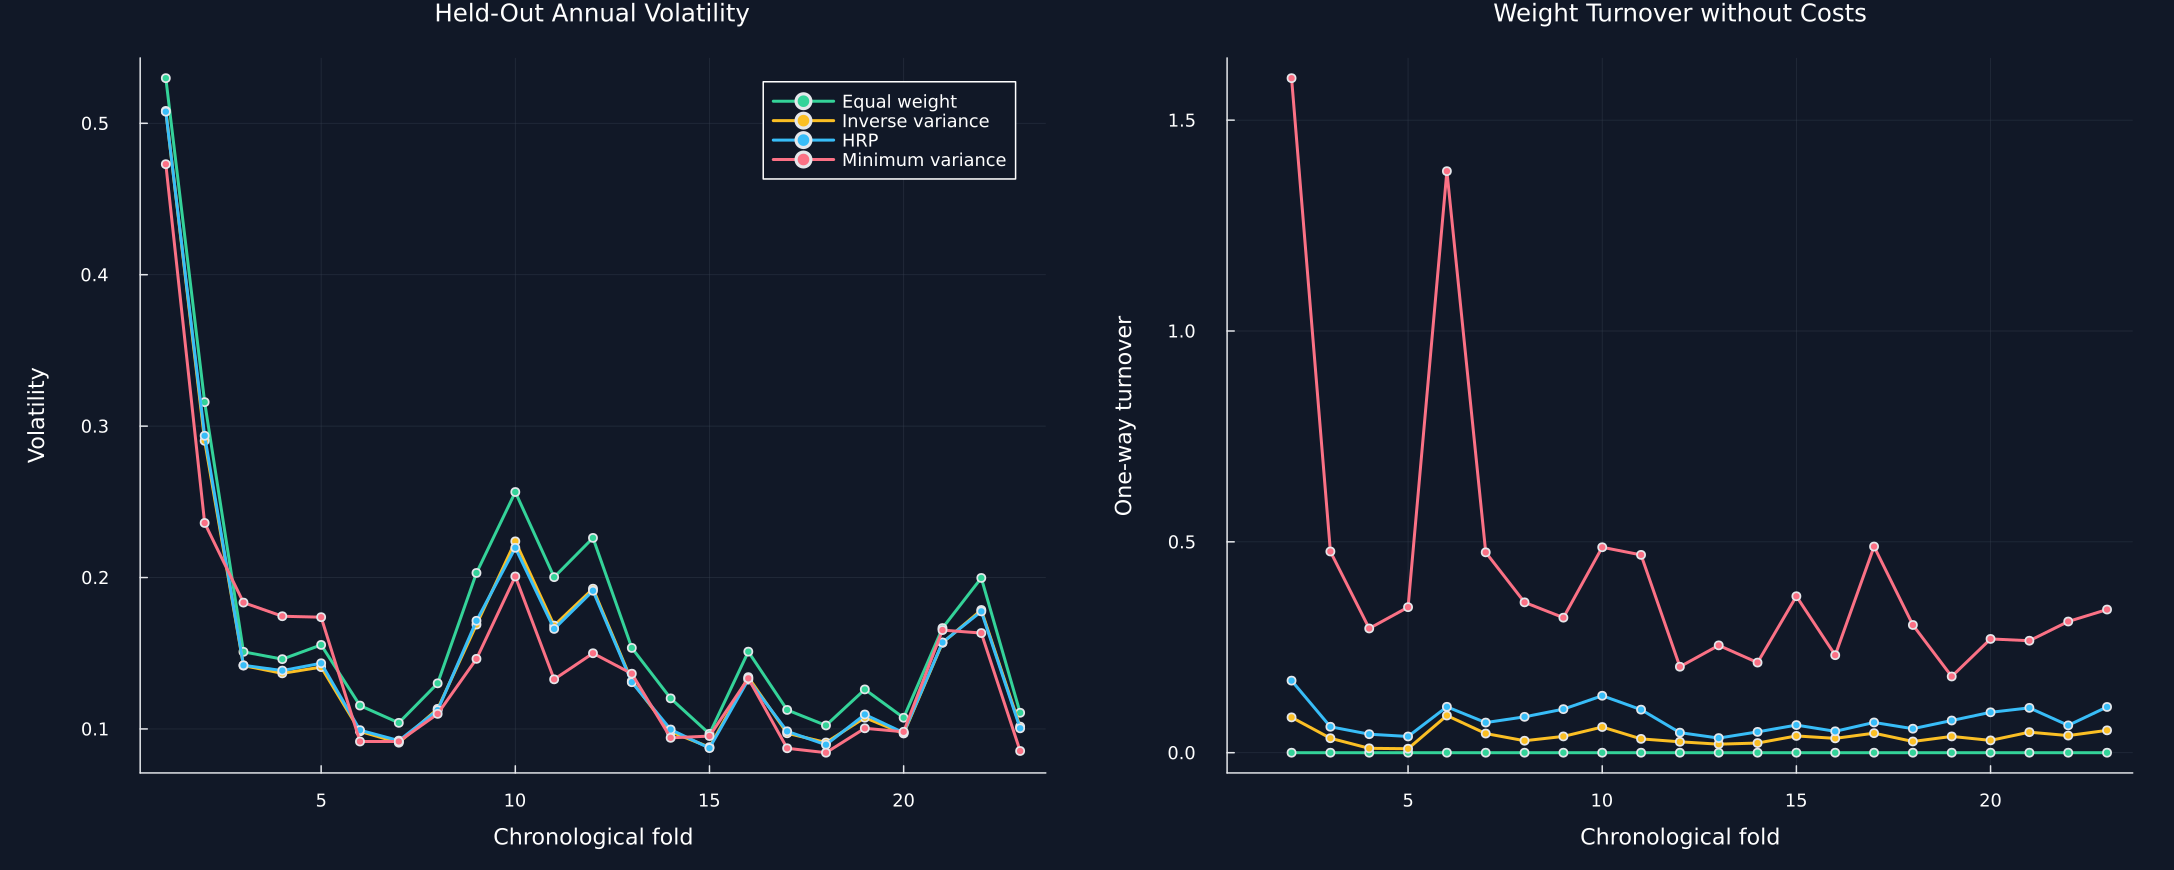

Row,Preliminary item,Chapter 21 location,Status
,String,String,String
1,Public hierarchy and dendrogram,Section 21.1,Included
2,Correlation distance matrix,Section 21.1,Included
3,Quasi-diagonal ordering,Sections 21.1 and 21.2,Included
4,Recursive HRP weights,Section 21.2,Included
5,Known clustered covariance,Section 21.3,Included
6,Repeated HRP and inverse-variance comparison,Section 21.3,Included
7,Weight-stability comparison,Section 21.3,Included
8,Saved preliminary result trace,Rerun and replaced by maintained tables,Included


Row,Quantity,Value
,String,Int64
1,Known-truth repetitions,60
2,Sensitivity fits,480
3,Generated turnover dates,12
4,Public rolling windows,23
5,Compared portfolio rules,4
6,Public observations,1760


In [4]:
rolling_rows = NamedTuple[]
previous_public_weights = Dict{String,Vector{Float64}}()
fold_count = 0
for (fold,training_end) in enumerate(252:63:length(dates)-63)
    training = public_sample[training_end-251:training_end,:]
    testing = public_sample[training_end+1:training_end+63,:]
    fitted = portfolio_set(cov(training)*252,cor(training))
    fold_count = fold
    for (method,weights) in fitted
        held_out = testing*weights
        turnover_value = haskey(previous_public_weights,method) ? turnover(weights,previous_public_weights[method]) : NaN
        push!(rolling_rows,(Fold=fold,train=string(dates[training_end]),test=string(dates[training_end+63]),Method=method,volatility=std(held_out)*sqrt(252),turnover=turnover_value,concentration=sum(abs2,weights),largest=maximum(abs,weights)))
        previous_public_weights[method] = weights
    end
end
public_rolling = DataFrame(rolling_rows)
rename!(public_rolling,["Fold","Training end","Test end","Method","Held-out annual volatility","Turnover","Weight concentration","Largest absolute weight"])
save_data(public_rolling,paths,"public_rolling_results")
winners = [group.Method[argmin(group[!,5])] for group in groupby(public_rolling,:Fold)]
summary_rows = NamedTuple[]
for method in sort(method_order)
    subset = public_rolling[public_rolling.Method.==method,:]
    push!(summary_rows,(Method=method,meanrisk=mean(subset[!,5]),medianrisk=median(subset[!,5]),wins=count(==(method),winners),turnover=finite_mean(subset[!,6]),concentration=median(subset[!,7]),largest=median(subset[!,8])))
end
public_risk_summary = DataFrame(summary_rows)
rename!(public_risk_summary,["Method","Mean held-out volatility","Median held-out volatility","Lowest-volatility folds","Mean turnover","Median concentration","Median largest absolute weight"])
rolling_design = DataFrame("Quantity"=>["Assets","Training observations","Held-out observations","Windows","Annualization factor","Costs included"],"Value"=>["16","252","63",string(fold_count),"252","No"])
table(rolling_design,"public_rolling_design","Chronological public comparison design.")
table(public_risk_summary,"public_rolling_summary","Held-out public risk, turnover, and concentration.")
p1 = plot(;title="Held-Out Annual Volatility",ylabel="Volatility",xlabel="Chronological fold",legend=:topright)
p2 = plot(;title="Weight Turnover without Costs",ylabel="One-way turnover",xlabel="Chronological fold",legend=false)
for (method,color) in zip(method_order,colors)
    subset = public_rolling[public_rolling.Method.==method,:]
    plot!(p1,subset.Fold,subset[!,5];color,marker=:circle,markersize=3,label=method)
    plot!(p2,subset.Fold,subset[!,6];color,marker=:circle,markersize=3,label=method)
end
save_figure(plot(p1,p2;layout=(1,2),size=(1450,580)),paths,"public_rolling_hrp_comparison")
preliminary_parity = DataFrame("Preliminary item"=>["Public hierarchy and dendrogram","Correlation distance matrix","Quasi-diagonal ordering","Recursive HRP weights","Known clustered covariance","Repeated HRP and inverse-variance comparison","Weight-stability comparison","Saved preliminary result trace"],"Chapter 21 location"=>["Section 21.1","Section 21.1","Sections 21.1 and 21.2","Section 21.2","Section 21.3","Section 21.3","Section 21.3","Rerun and replaced by maintained tables"],"Status"=>fill("Included",8))
table(preliminary_parity,"preliminary_hrp_parity","Coverage of preliminary HRP experiments.")
comparison_section_summary = DataFrame("Quantity"=>["Known-truth repetitions","Sensitivity fits","Generated turnover dates","Public rolling windows","Compared portfolio rules","Public observations"],"Value"=>[60,nrow(sensitivity_results),nrow(topology_turnover),fold_count,4,length(dates)])
table(comparison_section_summary,"comparison_section_summary","Section 21.3 numerical summary.")


## Tests

In [5]:
@assert size(true_covariance)==(24,24)
@assert minimum(eigvals(Symmetric(true_covariance)))>0
@assert diag(true_correlation)≈ones(24)
@assert nrow(repeated_results)==240
@assert all(nrow(group)==4 for group in groupby(repeated_results,:Repetition))
@assert all(repeated_results[!,3].>=1-1e-10)
@assert all(repeated_results[!,4].>=0)
@assert length(unique(repeated_summary.Method))==4
@assert nrow(paired_comparison)==3
@assert all(0 .<=paired_comparison[!,3].<=1)
@assert nrow(sensitivity_results)==480
@assert all(nrow(group)==2 for group in groupby(sensitivity_results,["Assets","Training observations","Within correlation","Repetition"]))
@assert all(sensitivity_results[!,7].>=1-1e-10)
@assert nrow(sensitivity_summary)==24
@assert nrow(topology_turnover)>=10
@assert all(topology_turnover[!,4].>=0)
@assert all(filter(isfinite,topology_turnover[!,2]).>=0)
@assert all(filter(isfinite,topology_turnover[!,3]).>=0)
@assert all(nrow(group)==4 for group in groupby(public_rolling,:Fold))
@assert sum(public_risk_summary[!,4])==fold_count
@assert all(public_risk_summary[!,2].>0)
@assert all(public_risk_summary[!,5].>=0)
@assert nrow(preliminary_parity)==8
@assert all(preliminary_parity.Status.=="Included")
@assert isfile(joinpath(paths.figures,"repeated_known_truth_portfolios.pdf"))
@assert isfile(joinpath(paths.figures,"sampling_sensitivity_heatmaps.pdf"))
@assert isfile(joinpath(paths.figures,"tree_turnover_diagnostics.pdf"))
@assert isfile(joinpath(paths.figures,"public_rolling_hrp_comparison.pdf"))
@assert isfile(joinpath(paths.tables,"repeated_known_truth_summary.tex"))
@assert isfile(joinpath(paths.tables,"public_rolling_summary.tex"))
